# Phase 1 — Chronological Split and Feature Engineering

**Follows:** `01_eda.ipynb`, section 8 (modeling plan).

**Scope:** decide the train / validation / test split, build the feature table, and *prove* the features don't leak future information. No models are trained here.

**Output:** `data/cache/features_{train,val,test}.parquet`, which Phase 2 (baseline) loads directly.

The logic lives in `src/data.py` and `src/features.py` so later notebooks reuse exactly the same pipeline. This notebook runs it and checks the results.

## 0. Setup

In [1]:
import sys, json, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # make `src` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_clean, CACHE_DIR, TARGET
from src import features as F

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 60)

In [2]:
t0 = time.time()
df = load_clean()          # first run parses the CSV (~2 min) and caches Parquet; later runs are fast
print(f"{len(df):,} rows loaded in {time.time() - t0:.0f}s")
print("Date range:", df["Transaction Datetime"].min(), "->", df["Transaction Datetime"].max())

24,386,900 rows loaded in 2s
Date range: 1991-01-02 07:10:00 -> 2020-02-28 23:58:00


## 1. Choosing the split

🎯 **Goal:** pick time-based cutoffs where every split has enough fraud cases to measure performance reliably.

💡 **Why it matters:** a random split lets the model train on 2019 and get tested on 2018. That isn't how a fraud model is deployed, and because fraud patterns drift over time it produces optimistic scores. Before choosing the cutoffs, look at how fraud is spread across years.

In [3]:
by_year = (df.groupby("Year")[TARGET]
             .agg(transactions="size", frauds=lambda s: (s == "Yes").sum()))
by_year["fraud_rate_pct"] = (by_year["frauds"] / by_year["transactions"] * 100).round(3)
by_year

,transactions,frauds,fraud_rate_pct
Year,,,
1991,1585,0,0.000
1992,5134,0,0.000
1993,8378,0,0.000
1994,14316,0,0.000
1995,20928,0,0.000
1996,29945,10,0.033
1997,49753,32,0.064
1998,78345,32,0.041
1999,118250,24,0.020


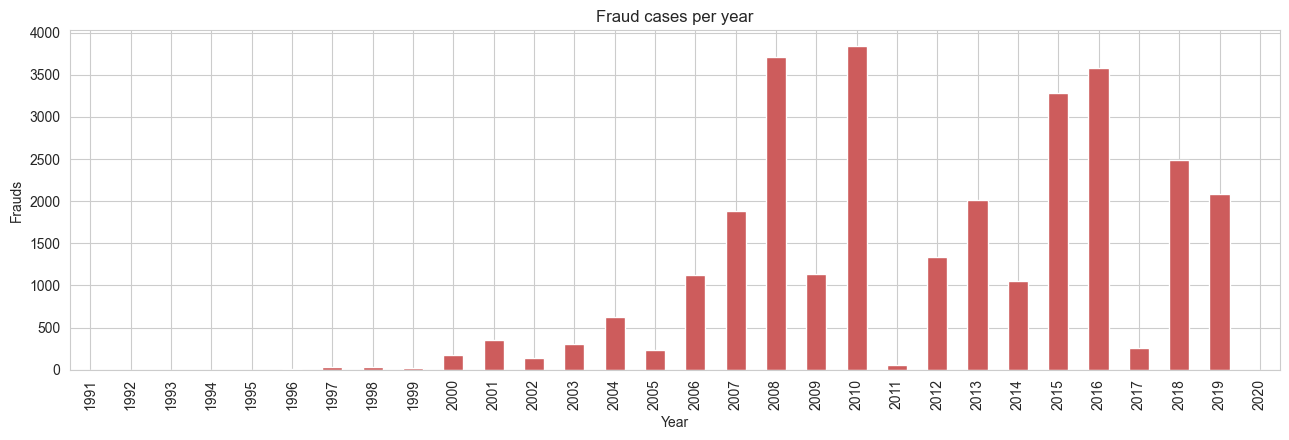

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
by_year["frauds"].plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Fraud cases per year")
ax.set_ylabel("Frauds")
plt.tight_layout()
plt.show()

### What the table shows

- **Fraud arrives in bursts.** Some years have thousands of cases, some very few (2011: 55, 2017: 255). The generator seems to simulate fraud campaigns, not a steady rate.
- **2020 has zero frauds in 336k transactions.** At the overall rate (~0.12%) we'd expect around 400. This almost certainly means the labels were never generated for the last two months. In production terms it's **label delay**: recent fraud hasn't been reported yet. Evaluating on 2020 would reward a model for predicting "never fraud", so 2020 is excluded.
- **2017 is too thin for validation.** 255 cases would make threshold choice and model comparison noisy.

### Decision

| Split | Period | Why |
|---|---|---|
| Train | 1991–2017 | All the history before the evaluation years |
| Validation | 2018 | A full year with 2,491 frauds, used for model choice, tuning and threshold |
| Test | 2019 | A full year with 2,087 frauds, scored **once** at the end |
| Excluded | Jan–Feb 2020 | Labels look missing |

The early years (1991–1995 have no fraud) stay in train. They add little to the model, but the per-card history features need them: a card's 2018 behavior is measured against its whole past.

In [5]:
split = F.split_name(df["Year"])
summary = (pd.DataFrame({"split": split, "fraud": df[TARGET] == "Yes", "dt": df["Transaction Datetime"]})
           .groupby("split")
           .agg(rows=("fraud", "size"), frauds=("fraud", "sum"), start=("dt", "min"), end=("dt", "max"))
           .loc[["train", "val", "test", "excluded"]])
summary["fraud_rate_pct"] = (summary["frauds"] / summary["rows"] * 100).round(3)
summary

,rows,frauds,start,end,fraud_rate_pct
split,,,,,
train,20604847,25179,1991-01-02 07:10:00,2017-12-31 23:59:00,0.122
val,1721615,2491,2018-01-01 00:03:00,2018-12-31 23:58:00,0.145
test,1723938,2087,2019-01-01 00:02:00,2019-12-31 23:59:00,0.121
excluded,336500,0,2020-01-01 00:03:00,2020-02-28 23:58:00,0.000


## 2. Building the features

🎯 **Goal:** turn the EDA findings into model inputs, keeping every feature something that would be known **at the moment the transaction is scored**.

| Group | Features | Comes from (EDA) |
|---|---|---|
| Amount | signed log amount, refund flag, zero-amount flag | Heavy right skew; negatives are refunds; $0 can be card testing |
| Time | hour, day of week | Fraud rate varies by hour |
| Channel & location | payment method, `is_online`, `is_international`, MCC | Online is 11% of volume but ~62% of fraud; missing state is structural, so it's encoded, not imputed |
| Errors | `has_error` + one flag per error type | `Errors?` is multi-label (e.g. "Bad PIN,Insufficient Balance") |
| High-cardinality IDs | merchant / city / zip **frequency** | 100k merchants and 13k cities: too many for one-hot. Frequencies are fitted on train only |
| **Card history** | transactions in the last 1h / 24h, amount and errors in the last 24h, time since the previous transaction, new merchant for this card, amount vs the card's past mean and z-score | How fraud usually shows: a burst of activity, a new merchant, an unusual amount |
| Card attributes | brand, type, chip, credit limit, card age at the transaction, amount / limit | Fixed per card, or computed at the transaction time |

**Deliberately left out of the default set** (kept in the files for the Phase 5 ablations):
- `merchant_state`: the suspected synthetic shortcut (foreign states show 50–100% fraud).
- User snapshots (age, income, debt, FICO, number of cards): recorded once at generation time, not at each transaction.
- `Card on Dark Web`: probably known only after the fraud. Not built at all.

**No feature uses fraud labels.** A "card had fraud before" feature would look great offline but wouldn't be available in production, because labels arrive weeks later.

### 2.1 Joining users and cards, with merge checks

🎯 **Goal:** attach card attributes (and the user snapshots kept for ablation) to 24M transactions, without the join silently corrupting the table.

💡 **Why it matters:** a join can go wrong without raising an error:
- **Duplicate keys** in a lookup table duplicate transactions, and the frauds with them.
- **Unmatched keys** quietly fill attributes with NaN.
- **Key type mismatches** (e.g. `int` vs `str`) match nothing at all.

`join_users_cards()` runs `merge_report()` **before** joining and raises `MergeError` on any FAIL. After joining, it re-checks the row count and that no matched row picked up a null.

**Efficiency:** only the two key columns of the big table go into the merge, and the small tables (2,000 users, 6,146 cards) are merged onto it, with integer keys downcast to `int16`/`int8`. On 24M rows the whole checked join takes about 13 seconds.

In [6]:
from src.data import merge_report, join_users_cards, load_users, load_cards, MergeError

merge_report(df, load_users(), load_cards())

,check,value,status
0,duplicate User keys in users,0,OK
1,"duplicate (User, Card) keys in cards",0,OK
2,dtype mismatch on User (int16 vs int16),0,OK
3,dtype mismatch on Card (int8 vs int8),0,OK
4,transaction users missing from users table,0,OK
5,transaction cards missing from cards table,0,OK
6,users with no transactions,0,INFO
7,cards with no transactions,7,INFO


All keys match. The 7 cards with no transactions are informational only, because a left join from transactions never touches them.

To confirm the checks actually fire, break the data on purpose: point 5 transactions at a card that doesn't exist.

In [7]:
broken = df.head(1_000).copy()
broken.loc[broken.index[:5], "Card"] = 99          # card 99 doesn't exist
try:
    join_users_cards(broken)
except MergeError as e:
    print("MergeError raised, as intended:")
    print(e)

MergeError raised, as intended:
Join pre-checks failed:
                                     check  value status
transaction cards missing from cards table      1   FAIL
                  -> transactions affected      5   FAIL


### 2.2 Build the full feature table

In [8]:
t0 = time.time()
splits = F.build_features(df)
print(f"Features built in {time.time() - t0:.0f}s")
for name, d in splits.items():
    print(f"{name:>5}: {d.shape[0]:>11,} rows x {d.shape[1]} cols | frauds {d['is_fraud'].sum():,}")

Features built in 60s
train:  20,604,847 rows x 45 cols | frauds 25,179
  val:   1,721,615 rows x 45 cols | frauds 2,491
 test:   1,723,938 rows x 45 cols | frauds 2,087


In [9]:
splits["val"][F.DEFAULT_FEATURES].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
amount_signed_log,1721615.0,NaN,NaN,NaN,2.922357,2.048261,-6.216606,2.306577,3.407179,4.158883,8.645273
is_refund,1721615.0,NaN,NaN,NaN,0.047812,0.213368,0.0,0.0,0.0,0.0,1.0
is_zero_amount,1721615.0,NaN,NaN,NaN,0.000792,0.028136,0.0,0.0,0.0,0.0,1.0
hour,1721615.0,NaN,NaN,NaN,12.394661,5.076575,0.0,9.0,12.0,16.0,23.0
day_of_week,1721615.0,NaN,NaN,NaN,3.062565,1.985227,0.0,1.0,3.0,5.0,6.0
use_chip,1721615,3,Chip Transaction,1215055,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_online,1721615.0,NaN,NaN,NaN,0.124088,0.329682,0.0,0.0,0.0,0.0,1.0
is_international,1721615.0,NaN,NaN,NaN,0.007045,0.083639,0.0,0.0,0.0,0.0,1.0
mcc,1721615,109,5411,205063,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_error,1721615.0,NaN,NaN,NaN,0.015729,0.124427,0.0,0.0,0.0,0.0,1.0


## 3. Leakage checks

🎯 **Goal:** show, not just claim, that the history features use only the past.

💡 **Why it matters:** a rolling window that accidentally includes the current row, or the future, inflates offline scores and then collapses in production. It's one of the most common bugs in fraud projects.

**Test 1: truncation invariance.** Compute the history features on data cut off at 2015, and on the full data. If the features only look backwards, every pre-2015 row must have *identical* values in both runs. Any future information would make them differ. (A 200-user subset keeps this fast; the code path is the same.)

In [10]:
users_subset = df["User"].unique()[:200]
sub = df[df["User"].isin(users_subset)].reset_index(drop=True)
cut = sub[sub["Year"] < 2015].reset_index(drop=True)

full_hist = F.add_card_history_features(sub, F.add_transaction_features(sub))
cut_hist = F.add_card_history_features(cut, F.add_transaction_features(cut))

pd.testing.assert_frame_equal(
    full_hist.loc[sub["Year"] < 2015, F.CARD_HISTORY_FEATURES].reset_index(drop=True),
    cut_hist[F.CARD_HISTORY_FEATURES],
)
print(f"Passed: {len(cut):,} pre-2015 rows have identical history features with and without the future data.")

Passed: 1,560,184 pre-2015 rows have identical history features with and without the future data.


**Test 2: brute-force recount.** The windowed features use a vectorized binary-search trick. Recompute a few rows the slow, obvious way and compare.

In [11]:
rng = np.random.default_rng(0)
rows = []
for i in rng.choice(len(sub), 8, replace=False):
    r = sub.loc[i]
    same_card = (sub["User"] == r["User"]) & (sub["Card"] == r["Card"])
    t = r["Transaction Datetime"]
    in_window = same_card & (sub.index < i) & (sub["Transaction Datetime"] >= t - pd.Timedelta("24h")) \
                & (sub["Transaction Datetime"] <= t)
    rows.append({"row": i,
                 "txns_24h (slow)": int(in_window.sum()), "txns_24h (pipeline)": int(full_hist.loc[i, "card_txns_24h"]),
                 "amount_24h (slow)": round(float(sub.loc[in_window, "Amount"].sum()), 2),
                 "amount_24h (pipeline)": round(float(full_hist.loc[i, "card_amount_24h"]), 2)})
check = pd.DataFrame(rows)
assert (check["txns_24h (slow)"] == check["txns_24h (pipeline)"]).all()
assert np.allclose(check["amount_24h (slow)"], check["amount_24h (pipeline)"], atol=0.05)
check

,row,txns_24h (slow),txns_24h (pipeline),amount_24h (slow),amount_24h (pipeline)
0,2057108,2,2,54.98,54.98
1,181957,2,2,20.77,20.77
2,39969,4,4,171.79,171.79
3,1236108,2,2,197.69,197.69
4,744441,3,3,181.95,181.95
5,652440,0,0,0.00,0.00
6,99088,0,0,0.00,0.00
7,1540398,4,4,59.09,59.09


**Test 3: encoders fitted on train only.** Merchants first seen after 2017 should get frequency 0 in validation and test. That's what happens in production when a new merchant appears. If this share were 0%, the encoder would have seen the future.

In [12]:
for name in ["train", "val", "test"]:
    d = splits[name]
    print(f"{name:>5}: {(d['merchant_freq'] == 0).mean():6.2%} of rows have a merchant unseen in training")

train:  0.00% of rows have a merchant unseen in training
  val:  0.30% of rows have a merchant unseen in training
 test:  0.34% of rows have a merchant unseen in training


## 4. Do the new features carry signal? (train only)

🎯 **Goal:** a sanity check that the history features behave the way fraud intuition says, before any model sees them.

💡 This uses the **training period only**. Looking at validation or test here would quietly steer feature choices with data that's supposed to stay unseen.

In [13]:
tr = splits["train"]
base_rate = tr["is_fraud"].mean() * 100

def fraud_rate_by(col, bins=None, labels=None):
    key = pd.cut(tr[col], bins=bins, labels=labels, right=False) if bins is not None else tr[col]
    g = tr.groupby(key, observed=True)["is_fraud"].agg(transactions="size", fraud_rate_pct="mean")
    g["fraud_rate_pct"] = (g["fraud_rate_pct"] * 100).round(3)
    g["lift_vs_base"] = (g["fraud_rate_pct"] / base_rate).round(1)
    return g

print(f"Train base fraud rate: {base_rate:.3f}%\n")
display(fraud_rate_by("card_txns_24h", bins=[0, 1, 3, 6, 10, np.inf], labels=["0", "1-2", "3-5", "6-9", "10+"]))
display(fraud_rate_by("card_errors_24h", bins=[0, 1, 2, np.inf], labels=["0", "1", "2+"]))
display(fraud_rate_by("is_new_merchant_for_card"))
display(fraud_rate_by("is_international"))

Train base fraud rate: 0.122%



,transactions,fraud_rate_pct,lift_vs_base
card_txns_24h,,,
0,4270970,0.060,0.5
1-2,8817193,0.098,0.8
3-5,5677508,0.166,1.4
6-9,1540826,0.258,2.1
10+,298350,0.195,1.6


,transactions,fraud_rate_pct,lift_vs_base
card_errors_24h,,,
0,19781227,0.115,0.9
1,740948,0.299,2.4
2+,82672,0.218,1.8


,transactions,fraud_rate_pct,lift_vs_base
is_new_merchant_for_card,,,
0,19750840,0.060,0.5
1,854007,1.566,12.8


,transactions,fraud_rate_pct,lift_vs_base
is_international,,,
0,20474638,0.113,0.9
1,130209,1.594,13.0


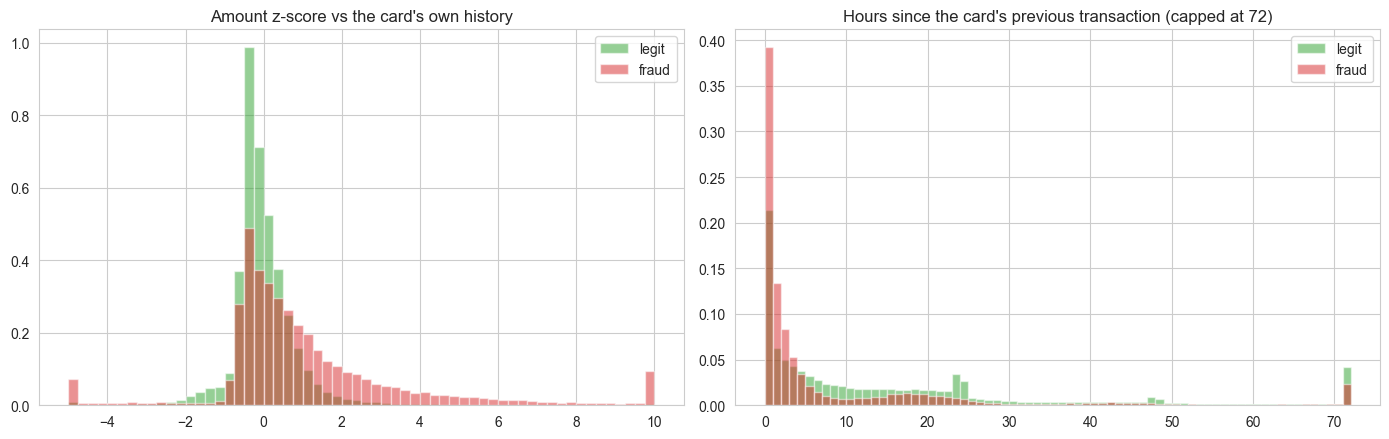

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
z = tr["amt_card_zscore"].clip(-5, 10)
for label, color in [(0, "#2ca02c"), (1, "#d62728")]:
    axes[0].hist(z[tr["is_fraud"] == label].dropna(), bins=60, density=True, alpha=0.5, color=color,
                 label="fraud" if label else "legit")
axes[0].set_title("Amount z-score vs the card's own history")
axes[0].legend()

gap_h = (tr["secs_since_prev_txn"] / 3600).clip(upper=72)
for label, color in [(0, "#2ca02c"), (1, "#d62728")]:
    axes[1].hist(gap_h[tr["is_fraud"] == label].dropna(), bins=72, density=True, alpha=0.5, color=color,
                 label="fraud" if label else "legit")
axes[1].set_title("Hours since the card's previous transaction (capped at 72)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Reading the results (training period)

- **`is_new_merchant_for_card` is the strongest history signal:** a first purchase at a merchant is fraud 1.57% of the time, **12.8× the base rate**. That's the classic pattern of a stolen card being used somewhere its owner never shops.
- **Activity bursts matter, but not monotonically.** Fraud rate climbs from 0.06% (no card activity in the past 24h) to 0.26% (6–9 transactions), then drops for 10+. Very heavy users are mostly legitimate, which is why the model needs the card's own baseline (`amt_card_zscore`, `secs_since_prev_txn`) and not just raw counts.
- **A recent error on the card more than doubles the risk** (2.4× after one error in 24h). That fits the card-testing pattern from EDA section 5.5.
- ⚠️ **`is_international` shows a 13× lift.** It's derived from `Merchant State`, so it carries the same suspected synthetic shortcut. It stays in the default set because the plan calls for it, but the Phase 5 "no geography" ablation must remove **both** `merchant_state` and `is_international` (`F.GEO_DERIVED_FEATURES`). Otherwise the shortcut survives under a different name.
- None of these lifts is implausibly large (hundreds×), so there's no sign of a label leaking through a feature.

## 5. Save the feature tables

Parquet keeps the dtypes (including categories) exactly, so Phase 2 loads these files and goes straight to modeling.

In [15]:
for name, d in splits.items():
    path = CACHE_DIR / f"features_{name}.parquet"
    d.to_parquet(path, index=False)
    print(f"{path.name}: {path.stat().st_size / 1e6:,.0f} MB")

feature_sets = {
    "default": F.DEFAULT_FEATURES,
    "user_snapshot": F.USER_SNAPSHOT_FEATURES,
    "shortcut": F.SHORTCUT_FEATURES,
    "geo_derived": F.GEO_DERIVED_FEATURES,
    "categorical": F.CATEGORICAL_FEATURES,
    "target": "is_fraud",
}
(CACHE_DIR / "feature_sets.json").write_text(json.dumps(feature_sets, indent=2))
print(f"Default feature count: {len(F.DEFAULT_FEATURES)}")

features_train.parquet: 707 MB


features_val.parquet: 61 MB


features_test.parquet: 62 MB
Default feature count: 36


## 6. Summary and next step

- **Split:** train 1991–2017, validation 2018, test 2019. 2020 is excluded because its labels look missing. Every evaluation split has 2,000+ frauds.
- **Features:** a default set of single-transaction, card-history and card-attribute features. `Merchant State` and the user snapshots are held back for the ablations. `is_international` carries the same geographic shortcut and must be dropped with it.
- **Leakage:** truncation invariance, a brute-force recount and the unseen-merchant share all check out.

**Next, Phase 2:** a class-weighted logistic regression baseline on the default feature set, evaluated with PR-AUC and recall at a fixed precision on the 2018 validation year.